<a href="https://colab.research.google.com/github/rivindu02/EN3160-Image-Processing-and-Computer-Vision/blob/main/Assignment02_Q1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Question 01

In [48]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import blob_log
from math import sqrt

In [50]:
# --- 2. Create a Feathered Mask to Robustly Remove the Horizon ---
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
height = image_gray.shape[0]

sky_cutoff = int(height * 0.49)

mask_hard = np.zeros(image_gray.shape, dtype="uint8")
mask_hard[sky_cutoff:, :] = 255
mask_feathered = cv2.GaussianBlur(mask_hard, (81, 81), 0)

In [59]:
# --- 3. Prepare Image for Detection ---
image_inverted = 255 - image_gray
image_clean_input = (image_inverted / 255.0 * mask_feathered / 255.0)
image_clean_input = (image_clean_input * 255).astype(np.uint8)

# --- 4. Use `blob_log` with the Definitive, Correct Tuning ---
min_radius = 2
max_radius = 15
min_sigma = min_radius / sqrt(2)
max_sigma = max_radius / sqrt(2)

# A high threshold is the correct way to eliminate noise and false positives.
# This forces the algorithm to only accept strong, valid detections.
blobs = blob_log(
    image_clean_input,
    min_sigma=min_sigma,
    max_sigma=max_sigma,
    num_sigma=8,
    threshold=0.29,  # Drastically increased threshold to reject all noise.
    overlap=0.9      # Strong overlap filter for final cleanup.
)

Final Detection: 41 sunflowers.
The range of σ (sigma) values used was: 1.41 to 10.61

Parameters of the 5 largest circles detected:

Rank       Center (y, x)        Radius (pixels)     
-------------------------------------------------------
#1         (275    , 0      ) 11.29               
#2         (338    , 282    ) 9.43                
#3         (255    , 106    ) 7.57                
#4         (261    , 178    ) 7.57                
#5         (328    , 179    ) 7.57                


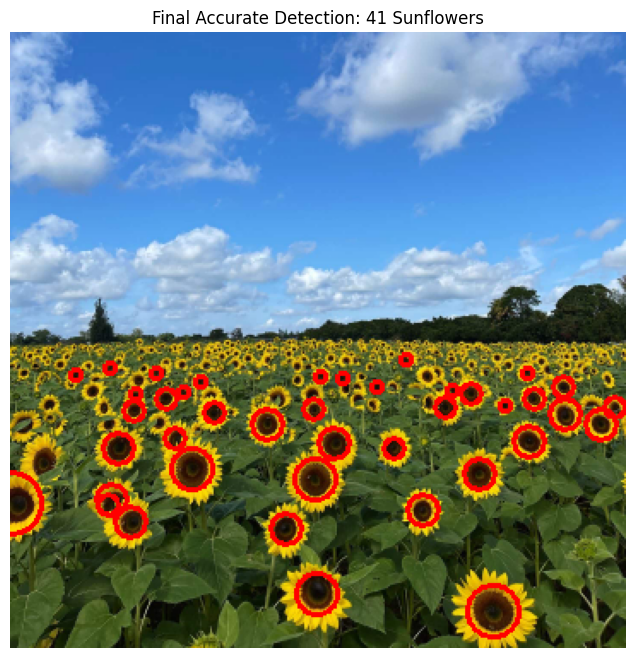

In [60]:
# --- 5. Report and Visualize the Final, Accurate Results ---
print(f"Final Detection: {len(blobs)} sunflowers.")
print(f"The range of σ (sigma) values used was: {min_sigma:.2f} to {max_sigma:.2f}")

blobs[:, 2] = blobs[:, 2] * sqrt(2)
final_blobs_sorted = sorted(blobs, key=lambda b: b[2], reverse=True)

print("\nParameters of the 5 largest circles detected:\n")
print("{:<10} {:<20} {:<20}".format("Rank", "Center (y, x)", "Radius (pixels)"))
print("-" * 55)
for i, (y, x, r) in enumerate(final_blobs_sorted[:5]):
    print("{:<10} ({:<7.0f}, {:<7.0f}) {:<20.2f}".format(f"#{i+1}", y, x, r))

image_with_circles = image.copy()
radius_scaling_factor = 1.6

for (y, x, r) in blobs:
    scaled_radius = int(r * radius_scaling_factor)
    cv2.circle(image_with_circles, (int(x), int(y)), scaled_radius, (0, 0, 255), 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(image_with_circles, cv2.COLOR_BGR2RGB))
plt.title(f'Final Accurate Detection: {len(blobs)} Sunflowers')
plt.axis('off')
plt.show()